In [ ]:
import os
from pathlib import Path

def get_project_root():
    current = Path.cwd().resolve()
    for candidate in [current, current.parent, current.parent.parent]:
        if (candidate / "data" / "raw").exists() or (candidate / "requirements.txt").exists():
            return candidate
    return current

PROJECT_ROOT = get_project_root()
os.chdir(PROJECT_ROOT)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import zipfile
import os
import shutil

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
    files = None

print("Libraries imported successfully.")


Libraries imported successfully.


In [ ]:
res_dir = PROJECT_ROOT / "results"
required_files = [
    res_dir / "regression" / "AcademiQ_Regression_Test_Results.csv",
    res_dir / "regression" / "AcademiQ_Regression_CV_Results.csv",
    res_dir / "classification" / "AcademiQ_Classification_Test_Results.csv",
    res_dir / "classification" / "AcademiQ_Classification_CV_Results.csv",
    res_dir / "clustering" / "AcademiQ_Clustering_Evaluation.csv",
    res_dir / "clustering" / "AcademiQ_Cluster_Score_Analysis.csv",
    res_dir / "feature_analysis" / "AcademiQ_Feature_Selection_Results.csv",
    res_dir / "feature_analysis" / "AcademiQ_PCA_Summary.csv"
]

missing = [str(f) for f in required_files if not f.exists()]

if missing:
    print("Warning: Missing required files:")
    for f in missing:
        print(" -", f)
else:
    print("All required results files found successfully across results/ subdirectories.")


All required result files are already stored locally and verified!


In [ ]:
res_dir = PROJECT_ROOT / "results"

regression_results = pd.read_csv(res_dir / "regression" / "AcademiQ_Regression_Test_Results.csv")
regression_cv = pd.read_csv(res_dir / "regression" / "AcademiQ_Regression_CV_Results.csv")
classification_results = pd.read_csv(res_dir / "classification" / "AcademiQ_Classification_Test_Results.csv")
classification_cv = pd.read_csv(res_dir / "classification" / "AcademiQ_Classification_CV_Results.csv")
clustering_results = pd.read_csv(res_dir / "clustering" / "AcademiQ_Clustering_Evaluation.csv")
cluster_scores = pd.read_csv(res_dir / "clustering" / "AcademiQ_Cluster_Score_Analysis.csv")
feature_results = pd.read_csv(res_dir / "feature_analysis" / "AcademiQ_Feature_Selection_Results.csv")
pca_summary = pd.read_csv(res_dir / "feature_analysis" / "AcademiQ_PCA_Summary.csv")

print("All results successfully loaded from results/ subdirectories.")


All project results loaded successfully.


In [ ]:
best_regression = regression_results.loc[
    regression_results["RMSE"].idxmin()
]

print("Best Regression Model:")
display(best_regression.to_frame().T)

Best Regression Model:


,Model,MAE,MSE,RMSE,R2 Score
1,Multiple Linear Regression,0.44995,3.252081,1.803353,0.769928


In [ ]:
best_classification = classification_results.loc[
    classification_results["F1 Score"].idxmax()
]

print("Best Classification Model:")
display(best_classification.to_frame().T)

Best Classification Model:


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.950832,0.951168,0.947731,0.949184


In [ ]:
best_clustering = clustering_results.loc[
    clustering_results["Silhouette_Score"].idxmax()
]

print("Best Silhouette Score:")
display(best_clustering.to_frame().T)

print("\nCluster-wise exam score analysis:")
display(cluster_scores)

Best Silhouette Score:


,K,Inertia,Silhouette_Score
0,2.0,62579.68245,0.058008



Cluster-wise exam score analysis:


,Cluster,count,mean,median,std,min,max
0,0,2590,67.727413,68.0,3.981492,57,101
1,1,2695,66.722820,67.0,3.800615,56,100


In [ ]:
print("Top 10 features based on F-score:")

display(
    feature_results
    .sort_values("F_Score", ascending=False)
    .head(10)
)

Top 10 features based on F-score:


,Feature,F_Score,P_Value
0,num__Attendance,2664.242099,0.000000e+00
1,num__Hours_Studied,1243.583979,7.877417e-245
2,num__Previous_Scores,162.874873,9.254935e-37
3,num__Tutoring_Sessions,131.985120,3.433500e-30
4,cat__Access_to_Resources_High,119.425433,1.661616e-27
5,cat__Parental_Involvement_High,107.530710,5.902585e-25
6,cat__Access_to_Resources_Low,97.010154,1.080646e-22
7,cat__Parental_Involvement_Low,62.852283,2.697887e-15
8,cat__Parental_Education_Level_Postgraduate,54.503895,1.792957e-13
9,cat__Learning_Disabilities_Yes,44.717692,2.510932e-11


In [ ]:
print("PCA Summary:")
display(pca_summary)

PCA Summary:


,Metric,Value
0,Original Features,43.000000
1,Retained Components,24.000000
2,Explained Variance,0.964216


In [ ]:
final_summary = pd.DataFrame([
    {
        "Analysis": "Regression",
        "Best_Model": best_regression["Model"],
        "Primary_Metric": "RMSE",
        "Metric_Value": best_regression["RMSE"]
    },
    {
        "Analysis": "Classification",
        "Best_Model": best_classification["Model"],
        "Primary_Metric": "Macro F1 Score",
        "Metric_Value": best_classification["F1 Score"]
    },
    {
        "Analysis": "Clustering",
        "Best_Model": f"K-Means (K={int(best_clustering['K'])})",
        "Primary_Metric": "Silhouette Score",
        "Metric_Value": best_clustering["Silhouette_Score"]
    }
])

display(final_summary.round(4))

final_dir = PROJECT_ROOT / "results" / "final"
final_dir.mkdir(parents=True, exist_ok=True)
final_summary.to_csv(
    final_dir / "AcademiQ_Final_Model_Summary.csv",
    index=False
)
print("Final summary saved successfully to results/final/AcademiQ_Final_Model_Summary.csv.")


,Analysis,Best_Model,Primary_Metric,Metric_Value
0,Regression,Multiple Linear Regression,RMSE,1.8034
1,Classification,Logistic Regression,Macro F1 Score,0.9492
2,Clustering,K-Means (K=2),Silhouette Score,0.0580


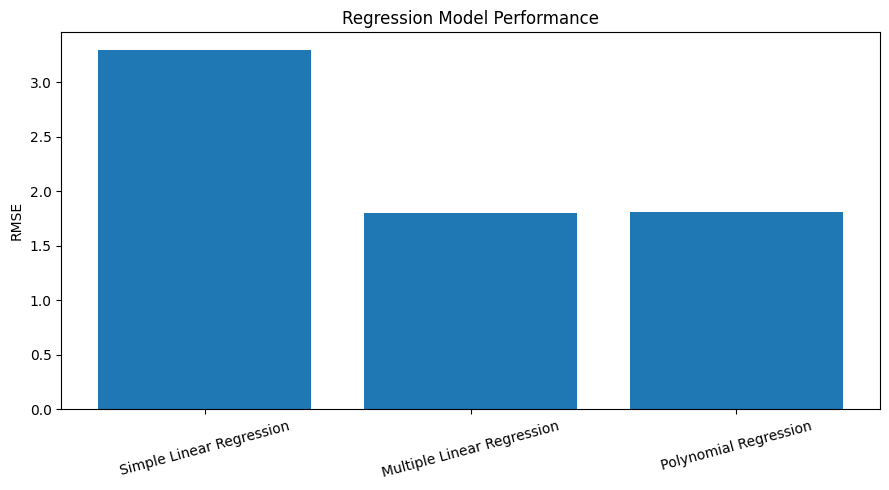

In [ ]:
plt.figure(figsize=(9, 5))

plt.bar(
    regression_results["Model"],
    regression_results["RMSE"]
)

plt.title("Regression Model Performance")
plt.ylabel("RMSE")
plt.xticks(rotation=15)
plt.tight_layout()

final_dir = PROJECT_ROOT / "results" / "final"
final_dir.mkdir(parents=True, exist_ok=True)
plt.savefig(final_dir / "AcademiQ_Regression_Comparison.png", dpi=300, bbox_inches="tight")
plt.show()


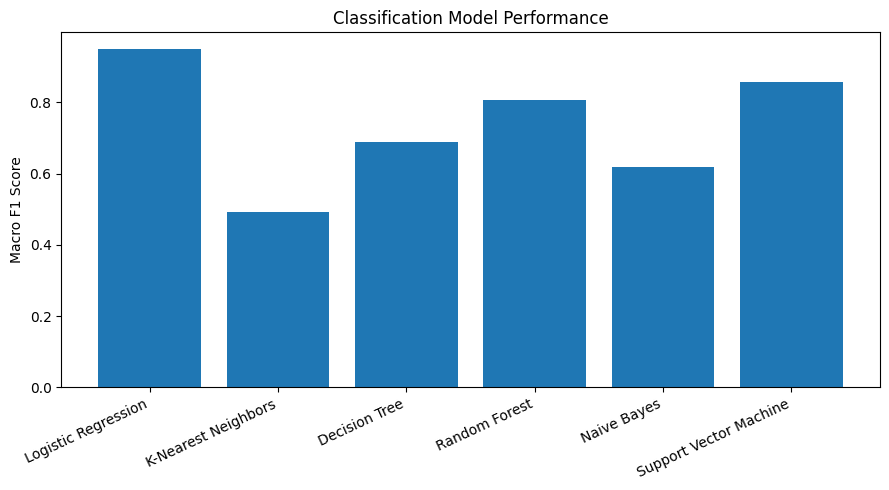

In [ ]:
plt.figure(figsize=(9, 5))

plt.bar(
    classification_results["Model"],
    classification_results["F1 Score"]
)

plt.title("Classification Model Performance")
plt.ylabel("Macro F1 Score")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()

final_dir = PROJECT_ROOT / "results" / "final"
final_dir.mkdir(parents=True, exist_ok=True)
plt.savefig(final_dir / "AcademiQ_Classification_Comparison.png", dpi=300, bbox_inches="tight")
plt.show()


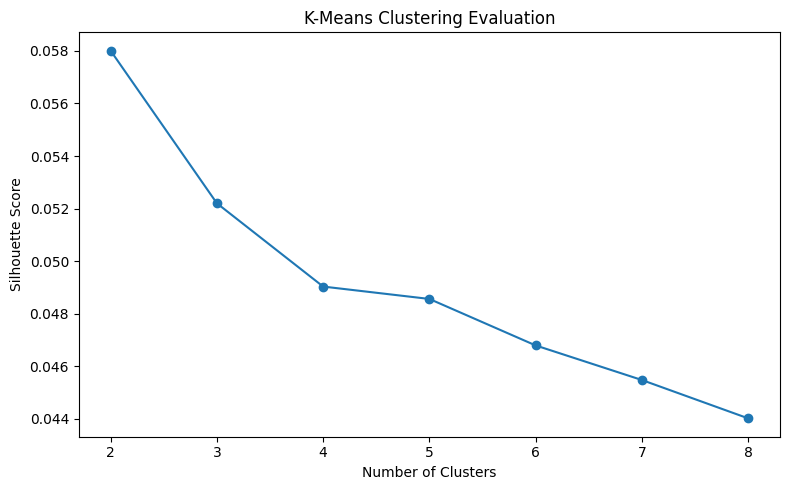

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    clustering_results["K"],
    clustering_results["Silhouette_Score"],
    marker="o"
)

plt.title("K-Means Clustering Evaluation")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.tight_layout()

final_dir = PROJECT_ROOT / "results" / "final"
final_dir.mkdir(parents=True, exist_ok=True)
plt.savefig(final_dir / "AcademiQ_Clustering_Comparison.png", dpi=300, bbox_inches="tight")
plt.show()


In [ ]:
best_regression = regression_results.sort_values(by="R2 Score", ascending=False).iloc[0]
best_classification = classification_results.sort_values(by="F1 Score", ascending=False).iloc[0]
best_clustering = clustering_results.sort_values(by="Silhouette_Score", ascending=False).iloc[0]

readme = f"""# AcademiQ: Applied Machine Learning Framework for Academic Performance Prediction

AcademiQ is an integrated, end-to-end Machine Learning research pipeline designed to analyze, predict, and profile student examination performance using multi-dimensional behavioural and demographic factors.

## Dataset Overview

The investigation analyzes the **Student Performance Factors** benchmark dataset obtained from **Kaggle**:
- **Total Observations:** 6,607 student records
- **Total Columns:** 20 (19 predictor features + 1 target variable)
- **Target Variable:** `Exam_Score` (continuous grade on a 0–100 scale)
- **Predictor Features:** Academic habits (e.g., `Hours_Studied`, `Attendance`, `Tutoring_Sessions`, `Previous_Scores`), lifestyle factors (e.g., `Sleep_Hours`, `Physical_Activity`), and demographic/institutional attributes (e.g., `Parental_Involvement`, `Access_to_Resources`, `Teacher_Quality`, `School_Type`).
- **Data Quality Handling:** Missing categorical values in three features (`Teacher_Quality`, `Parental_Education_Level`, `Distance_from_Home`) are explicitly imputed as `'Missing'`, and one recorded target outlier (`Exam_Score = 101`) is adjusted to 100 before dataset partitioning to ensure data integrity.

## Three Machine Learning Perspectives

Rather than introducing an artificial or overly complex algorithm, AcademiQ's central contribution is the complementary, multi-paradigm evaluation of the same student cohort across three distinct analytical lenses:

1. **Regression (Continuous Score Estimation):**
   Estimates a student's continuous exam score, providing fine-grained performance predictions and identifying the quantitative impact of study hours and attendance rates.
2. **Classification (Performance Tier Assignment):**
   Assigns students into actionable academic categories (`Developing`, `Proficient`, or `Advanced`) derived from empirical score tertiles, enabling targeted educational interventions.
3. **Clustering (Exploratory Student Profiling):**
   Explores latent behavioral patterns and lifestyle similarities across students without using examination labels.

> **Methodological Note on Clustering:**
> The optimal clustering model ($K=2$) achieves a silhouette score of approximately **0.0580**. This modest score reflects overlapping, continuous multivariate distributions rather than distinctly separated, isolated student archetypes. Clustering is therefore utilized for exploratory profiling along a continuum, rather than discrete natural classification.

## Quick Start & Setup

The project is designed to run in a clean, self-contained Python virtual environment. It has been successfully tested on **Python 3.13.4** (Windows 64-bit).

### 1. Environment Setup (Windows PowerShell)

```powershell
python -m venv venv
.\venv\Scripts\activate
pip install -r requirements.txt
```

### 2. Execution Instructions

Execute the notebooks sequentially from fresh kernels in the documented order:

1. `notebooks/AcademiQ_01_EDA.ipynb` — Exploratory Data Analysis & Anomaly Detection
2. `notebooks/AcademiQ_02_Preprocessing.ipynb` — Leakage-Safe Data Preprocessing & Splitting
3. `notebooks/AcademiQ_03_Regression.ipynb` — Continuous Score Prediction Modeling
4. `notebooks/AcademiQ_04_Classification.ipynb` — Performance Category Tier Classification
5. `notebooks/AcademiQ_05_Clustering.ipynb` — Unsupervised Student Profiling & Silhouette Analysis
6. `notebooks/AcademiQ_06_PCA_Feature_Analysis.ipynb` — Feature Selection & Dimensionality Reduction
7. `notebooks/AcademiQ_07_Final_Integration.ipynb` — Multi-Paradigm Synthesis & Comparison Visualizations

> **Note:** Each notebook automatically detects the project root directory regardless of whether it is launched from the project root or from inside `notebooks/`. Notebook 07 completes the pipeline by generating the master summary table and comparative visualization plots in `results/final/`.

## Pipeline Architecture

The investigation executes across seven sequential stages:

### 1. Exploratory Data Analysis (`notebooks/AcademiQ_01_EDA.ipynb`)
- Bivariate screening, distribution analysis, and anomaly detection.
- Missing value audit in categorical features (`Teacher_Quality`, `Parental_Education_Level`, `Distance_from_Home`).
- Correlation analysis showing `Attendance` (r = 0.58) and `Hours_Studied` (r = 0.45) as principal correlates.

### 2. Preprocessing & Leakage Prevention (`notebooks/AcademiQ_02_Preprocessing.ipynb`)
- Outlier boundary enforcement prior to partitioning.
- Missing category imputation with explicit 'Missing' category.
- Leakage-free 80:20 Train-Test split (`random_state=42`).
- StandardScaler on numerical features, OneHotEncoder on categorical attributes.

### 3. Regression Modeling (`notebooks/AcademiQ_03_Regression.ipynb`)
- Architectures: Simple Linear Regression, Multiple Linear Regression, Polynomial Regression (degree 2).
- Validation: 5-fold cross-validation inside pipeline structures.
- Primary Metrics: MAE, MSE, RMSE, R2.

### 4. Classification Modeling (`notebooks/AcademiQ_04_Classification.ipynb`)
- Discretization: Target tertiles derived strictly from training data quantiles.
- Classifiers: Logistic Regression, KNN, Decision Tree, Random Forest, Naive Bayes, Support Vector Machine (RBF).
- Metrics: Accuracy, Macro Precision, Macro Recall, Macro F1, Confusion Matrix, 5-fold CV.

### 5. Exploratory Clustering (`notebooks/AcademiQ_05_Clustering.ipynb`)
- Algorithm: K-Means clustering on 43 preprocessed features.
- Optimal K Selection: Elbow curve and Silhouette analysis.
- Methodological Finding: Silhouette score (0.0580) reflects overlapping continuous distributions; clustering serves exploratory profiling rather than distinct classification.

### 6. Feature Selection & PCA (`notebooks/AcademiQ_06_PCA_Feature_Analysis.ipynb`)
- SelectKBest: Univariate F-test identifying Attendance and Hours Studied as dominant features.
- PCA: 24 principal components capture >95% (96.42%) cumulative explained variance.

## Benchmark Results

### Regression Performance
- **Best Model:** {best_regression['Model']}
- **Test MAE:** {best_regression['MAE']:.4f}
- **Test RMSE:** {best_regression['RMSE']:.4f}
- **Test R2:** {best_regression['R2 Score']:.4f}

### Classification Performance
- **Best Model:** {best_classification['Model']}
- **Test Accuracy:** {best_classification['Accuracy']:.4f}
- **Test Macro F1:** {best_classification['F1 Score']:.4f}

### Clustering Profile
- **Optimal K:** {int(best_clustering['K'])}
- **Silhouette Score:** {best_clustering['Silhouette_Score']:.4f}
- **Interpretation:** Continuous multivariate distribution with exploratory student grouping.

## Technologies Used

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- Joblib

## Project Structure

```
PROJECT 2.0/
|-- notebooks/
|   |-- AcademiQ_01_EDA.ipynb                   # Stage 1: Exploratory Data Analysis
|   |-- AcademiQ_02_Preprocessing.ipynb         # Stage 2: Leakage-Safe Data Preprocessing
|   |-- AcademiQ_03_Regression.ipynb            # Stage 3: Score Prediction Regression
|   |-- AcademiQ_04_Classification.ipynb        # Stage 4: Performance Tier Classification
|   |-- AcademiQ_05_Clustering.ipynb            # Stage 5: Unsupervised Student Profiling
|   |-- AcademiQ_06_PCA_Feature_Analysis.ipynb  # Stage 6: Feature Selection & PCA
|   `-- AcademiQ_07_Final_Integration.ipynb     # Stage 7: Synthesis & Packaging
|-- data/
|   |-- raw/
|   |   `-- Student Performance Factors.csv     # Raw Dataset
|   `-- processed/                              # Cleaned, Preprocessed, Clustered, and PCA Datasets
|       |-- AcademiQ_Train_Cleaned.csv
|       |-- AcademiQ_Test_Cleaned.csv
|       |-- AcademiQ_Train_Preprocessed.csv
|       |-- AcademiQ_Test_Preprocessed.csv
|       |-- AcademiQ_Train_Clustered.csv
|       |-- AcademiQ_Test_Clustered.csv
|       |-- AcademiQ_Train_PCA.csv
|       `-- AcademiQ_Test_PCA.csv
|-- models/                                     # Serialized Scikit-learn Pipelines & Estimators
|   |-- AcademiQ_Simple_Linear_Regression.pkl
|   |-- AcademiQ_Multiple_Linear_Regression.pkl
|   |-- AcademiQ_Polynomial_Regression.pkl
|   |-- AcademiQ_logistic_regression.pkl
|   |-- AcademiQ_k_nearest_neighbors.pkl
|   |-- AcademiQ_decision_tree.pkl
|   |-- AcademiQ_random_forest.pkl
|   |-- AcademiQ_naive_bayes.pkl
|   |-- AcademiQ_support_vector_machine.pkl
|   |-- AcademiQ_KMeans_Model.pkl
|   |-- AcademiQ_Clustering_Preprocessor.pkl
|   |-- AcademiQ_Clustering_Pipeline.pkl
|   |-- AcademiQ_PCA_Preprocessor.pkl
|   |-- AcademiQ_Feature_Selector.pkl
|   |-- AcademiQ_PCA_Model.pkl
|   `-- AcademiQ_PCA_Pipeline.pkl
|-- results/
|   |-- regression/                             # Regression evaluation tables (Test & CV)
|   |-- classification/                         # Classification evaluation tables (Test, CV & Thresholds)
|   |-- clustering/                             # Clustering evaluations and profile tables
|   |-- feature_analysis/                       # Feature importance scores and PCA summaries
|   `-- final/                                  # Master summary table and comparative visualization figures
|-- docs/
|   `-- AcademiQ_EDA_Summary.csv                # Dataset profiling summary metrics
|-- requirements.txt                            # Verified environment dependencies
`-- README.md                                   # Comprehensive project documentation
```

## Limitations

- Statistical associations do not imply direct causation.
- Performance category boundaries are derived from the empirical sample distribution.
- Clustering profiles describe general tendencies along a continuum rather than isolated student archetypes.
"""

readme_path = PROJECT_ROOT / "README.md"
with open(readme_path, "w", encoding="utf-8") as file:
    file.write(readme)

print("README.md generated successfully at project root.")


README.md generated successfully.


### 7. Package Outputs for Academic Submission
This step bundles all generated plots, summaries, and documentation into a single `.zip` file to fulfill packaging and delivery requirements.

In [ ]:
print("All integrated synthesis tables, plots, and README documentation verified in results/final/ and root.")
